# SAMSum — Exploratory Data Analysis

**Goal:** understand the data before modelling, and turn each finding into a concrete decision in
`config/params.yaml` (truncation lengths, validation rules, cleaning).

**Prerequisite:** run Stages 1–2 first so `data/raw/` and `data/validated/` exist:

```bash
python -m summarizer.pipeline.training_pipeline --stages ingestion validation
```

Each section ends with an **Insight** box. Numbers quoted there were measured on the dataset commit recorded
in `artifacts/reports/ingestion_stats.json`. If you re-run on a newer commit, re-read the printed outputs.

| # | Section |
|---|---|
| 1 | Setup |
| 2 | Shape, schema, samples |
| 3 | Missing values, duplicates, leakage |
| 4 | Dialogue & summary length distributions |
| 5 | Token lengths (PEGASUS tokenizer) → truncation settings |
| 6 | Compression ratio & length relationship |
| 7 | Dialogue structure: turns and speakers |
| 8 | Word frequency & most common words |
| 9 | How abstractive are the summaries? |
| 10 | Outlier analysis |
| 11 | Key takeaways → decisions |

## 1. Setup

In [1]:
import json
import os
import re
import warnings
from collections import Counter
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

os.environ.setdefault("LOG_TO_FILE", "false")
warnings.filterwarnings("ignore", message="IProgress not found")  # notebook progress-bar notice
from summarizer.constants import PROJECT_ROOT
from summarizer.utils.text_stats import word_counts

RAW, VALID = PROJECT_ROOT / "data" / "raw", PROJECT_ROOT / "data" / "validated"
REPORTS = PROJECT_ROOT / "artifacts" / "reports"
FIGURES = REPORTS / "figures"
FIGURES.mkdir(parents=True, exist_ok=True)
SPLITS = ["train", "validation", "test"]

# --- Chart style: light surface, recessive grid/axes, thin marks -------------
SURFACE, INK, INK_2, GRID = "#fcfcfb", "#0b0b0b", "#52514e", "#e4e3de"
BLUE, ORANGE, AQUA = "#2a78d6", "#eb6834", "#1baf7a"   # categorical slots 1-3, fixed order
plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "figure.dpi": 110, "figure.figsize": (9, 4),
    "axes.edgecolor": GRID, "axes.labelcolor": INK_2, "axes.titlecolor": INK,
    "axes.titlesize": 12, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "axes.axisbelow": True, "grid.color": GRID, "grid.linewidth": 0.6,
    "xtick.color": INK_2, "ytick.color": INK_2, "text.color": INK, "font.size": 10,
    "legend.frameon": False,
})

def savefig(fig, name):
    fig.tight_layout()
    fig.savefig(FIGURES / f"{name}.png", bbox_inches="tight")

def hist(ax, values, bins, color=BLUE):
    ax.hist(values, bins=bins, color=color, edgecolor=SURFACE, linewidth=0.8)

def mark(ax, x, label, color=INK_2, ls="--"):
    ax.axvline(x, color=color, linestyle=ls, linewidth=1.2)
    ax.annotate(label, (x, 1), xycoords=("data", "axes fraction"), xytext=(4, -12),
                textcoords="offset points", color=INK_2, fontsize=9)

raw = {s: pd.read_csv(RAW / f"{s}.csv", dtype=object) for s in SPLITS}
val = {s: pd.read_csv(VALID / f"{s}.csv", dtype=object) for s in SPLITS}
train = val["train"].copy()
train["dialogue_words"] = word_counts(train["dialogue"])
train["summary_words"] = word_counts(train["summary"])
train["compression_ratio"] = train["dialogue_words"] / train["summary_words"]
print("dataset commit:", json.loads((REPORTS / "ingestion_stats.json").read_text())["resolved_commit"])

dataset commit: 6b929ff10edec703164e3ddb2e94aae058c9ab5f


## 2. Shape, schema and samples

In [2]:
shape = pd.DataFrame({s: {"rows (raw)": len(raw[s]), "rows (validated)": len(val[s]),
                          "columns": ", ".join(raw[s].columns)} for s in SPLITS}).T
shape

,rows (raw),rows (validated),columns
train,14731,14635,"id, dialogue, summary"
validation,818,818,"id, dialogue, summary"
test,819,819,"id, dialogue, summary"


In [3]:
for _, row in raw["train"].sample(2, random_state=7).iterrows():
    print(f"--- id {row.id} ---\n{row.dialogue}\n>>> SUMMARY: {row.summary}\n")

--- id 13810222 ---
Griff: hello buddy
Tea: hi
Griff: whats up?
Tea: reading
Griff: wanna go out?
Tea: yeah
Griff: i just wanted walk around
Tea: will be great
Griff: good
Griff: so see you in the park?
Tea: ok
Tea: in 10 mins?
Griff: okay
>>> SUMMARY: Griff and Tea will meet in 10 minutes to have a walk in the park.

--- id 13716819 ---
Rose: I bought new jacket:) the other one got worn down
Bree: Let me see! I thought you're broke totally
Rose: Yeah, well, my mom funded part of this shopping
Lily: Part:D? Probably she covered whole price
Rose: No, no, no! Of course not, she paid half of it
Bree: Does it really matter? I feel like we're gonna start fighting abut Rose's shopping, wtf?
Lily: I'm chilling, not saying anything
Bree: Well, I hope so:) Where did you find it?
Rose: You know this place, it's this second hand on 1st Ave and Pride St
Bree: OOOOh! I love this place, you can find really good vintage clothes there
Lily: Why you guys didn't tell me about this place ever?
Bree: Duh,

> **Insight.** Three string columns: `id`, `dialogue` (one `Speaker: message` line per turn, separated by `\n`)
> and `summary`. Train has about 14.7k rows and validation/test about 0.8k each, the official SAMSum split, which we
> keep so our ROUGE stays comparable with published results. The summaries are **third-person and abstractive**:
> they name the speakers and paraphrase ("Amanda baked cookies and will bring Jerry some tomorrow") instead of
> copying lines. That is why an abstractive (generative) model is needed.

## 3. Missing values, duplicates and leakage

In [4]:
rows = {}
for s in SPLITS:
    df = raw[s]
    rows[s] = {
        "null id/dialogue/summary": int(df[["id", "dialogue", "summary"]].isna().sum().sum()),
        "duplicate ids": int(df["id"].duplicated().sum()),
        "repeated dialogue texts": int(df["dialogue"].duplicated().sum()),
        "exact (dialogue, summary) duplicates": int(df.duplicated(["dialogue", "summary"]).sum()),
    }
train_d = set(raw["train"]["dialogue"])
for other in ("validation", "test"):
    print(f"distinct dialogues shared by train and {other}: {len(train_d & set(raw[other]['dialogue']))}")
pd.DataFrame(rows).T

distinct dialogues shared by train and validation: 47
distinct dialogues shared by train and test: 42


,null id/dialogue/summary,duplicate ids,repeated dialogue texts,"exact (dialogue, summary) duplicates"
train,0,0,476,1
validation,0,0,0,0
test,0,0,0,0


In [5]:
report = json.loads((REPORTS / "validation_report.json").read_text())
checks = pd.DataFrame([{"split": s, **c} for s, r in report["splits"].items() for c in r["checks"]])
checks = checks[checks["count"] > 0][["split", "severity", "name", "count", "description"]]
checks.sort_values(["severity", "count"], ascending=[True, False])

,split,severity,name,count,description
14,train,drop,cross_split_leakage,93,train dialogue also appears in validation/test
6,train,drop,summary_too_short,2,summary has fewer than 2 words
8,train,drop,duplicate_pair,1,"identical (dialogue, summary) pair already seen"
10,train,warning,contains_media_placeholder,2629,dialogue contains attachment tags such as <fil...
13,train,warning,shared_dialogue_multiple_summaries,941,dialogue appears more than once with different...
12,train,warning,dialogue_length_outlier,536,dialogue words above the IQR fence (262)
25,validation,warning,contains_media_placeholder,148,dialogue contains attachment tags such as <fil...
39,test,warning,contains_media_placeholder,140,dialogue contains attachment tags such as <fil...
9,train,warning,summary_longer_than_dialogue,61,summary has at least as many words as the dial...
41,test,warning,dialogue_length_outlier,41,dialogue words above the IQR fence (252)


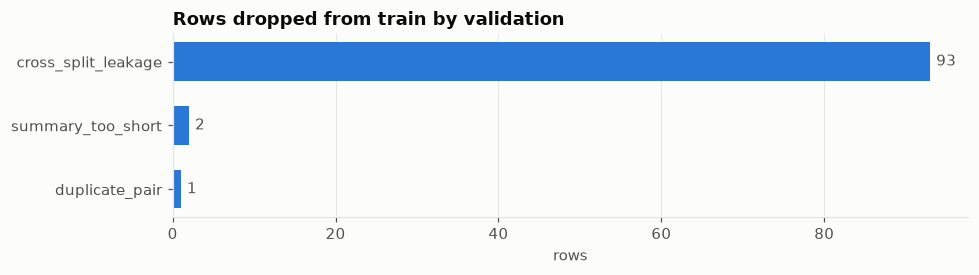

In [6]:
drops = checks[(checks.split == "train") & (checks.severity == "drop")].sort_values("count")
fig, ax = plt.subplots(figsize=(9, 2.6))
ax.barh(drops["name"], drops["count"], color=BLUE, height=0.6)
for y, v in enumerate(drops["count"]):
    ax.annotate(str(v), (v, y), xytext=(4, 0), textcoords="offset points", va="center", color=INK_2)
ax.set_title("Rows dropped from train by validation")
ax.set_xlabel("rows"); ax.grid(axis="y", visible=False)
savefig(fig, "01_validation_drops")

> **Insight.** The data is clean at the field level: no nulls and no duplicate ids. Three problems still mattered:
>
> * **Train/test leakage.** 42 test dialogues and 47 validation dialogues also appear in train. Trained on as-is,
>   the model would partly *memorise test answers* and ROUGE would be inflated. Validation removes 93 such rows from
>   **train** (never from test, which must stay comparable with other work).
> * **Junk references.** Two summaries are placeholder text (`"test"`, `"yyy"`) and are dropped by `min_summary_words`.
> * **Repeated dialogues ≠ duplicates.** About 460 dialogues appear 2–4 times in train, but with *different* summaries:
>   these are multiple human annotations. They are kept, because they teach the model several valid paraphrases. Only
>   one row is an exact (dialogue, summary) duplicate.
>
> In total, train loses 0.65% of rows; validation and test lose none.

## 4. Dialogue and summary length distributions (words)

In [7]:
train[["dialogue_words", "summary_words"]].describe(percentiles=[.25, .5, .75, .95, .99]).round(1).T

,count,mean,std,min,25%,50%,75%,95%,99%,max
dialogue_words,14635.0,93.7,74.0,7.0,39.0,73.0,127.0,237.0,351.0,803.0
summary_words,14635.0,20.3,11.1,2.0,12.0,18.0,27.0,43.0,53.0,64.0


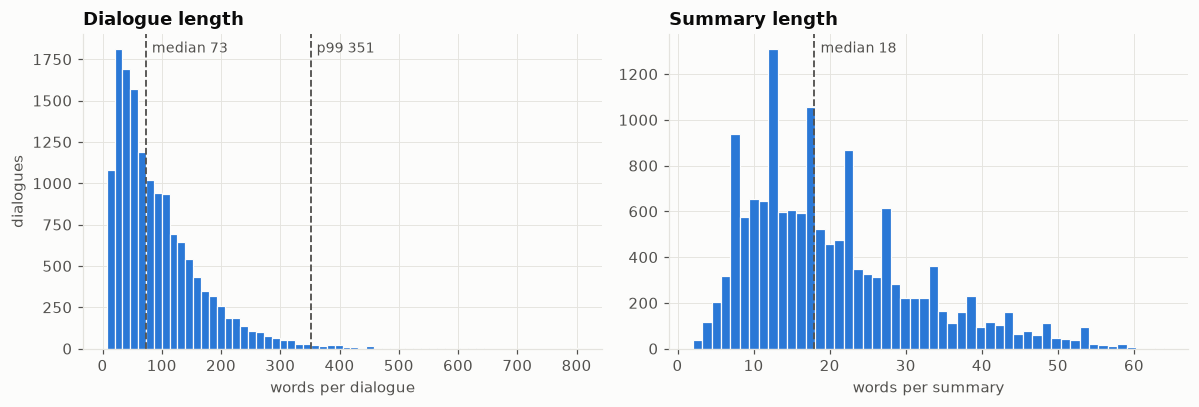

In [8]:
fig, (a1, a2) = plt.subplots(1, 2, figsize=(11, 3.8))
hist(a1, train["dialogue_words"], bins=60)
mark(a1, train["dialogue_words"].median(), f"median {train['dialogue_words'].median():.0f}")
mark(a1, train["dialogue_words"].quantile(.99), f"p99 {train['dialogue_words'].quantile(.99):.0f}")
a1.set_title("Dialogue length"); a1.set_xlabel("words per dialogue"); a1.set_ylabel("dialogues")
hist(a2, train["summary_words"], bins=50)
mark(a2, train["summary_words"].median(), f"median {train['summary_words'].median():.0f}")
a2.set_title("Summary length"); a2.set_xlabel("words per summary")
savefig(fig, "02_length_distributions")

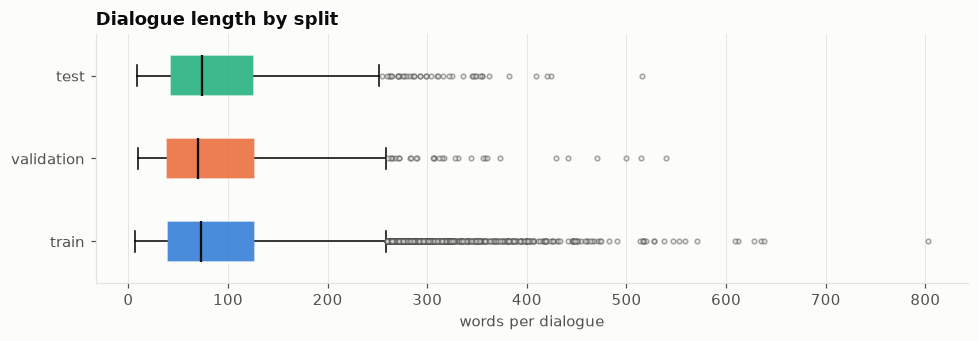

In [9]:
fig, ax = plt.subplots(figsize=(9, 3.2))
data = [word_counts(val[s]["dialogue"]) for s in SPLITS]
bp = ax.boxplot(data, orientation="horizontal", tick_labels=SPLITS, widths=0.5, patch_artist=True,
                flierprops=dict(marker="o", markersize=3, markerfacecolor=GRID, markeredgecolor=INK_2, alpha=.5),
                medianprops=dict(color=INK, linewidth=1.5))
for patch, color in zip(bp["boxes"], [BLUE, ORANGE, AQUA]):
    patch.set(facecolor=color, alpha=.85, edgecolor=SURFACE)
ax.set_title("Dialogue length by split"); ax.set_xlabel("words per dialogue"); ax.grid(axis="y", visible=False)
savefig(fig, "03_length_by_split")

> **Insight.** Both distributions are **right-skewed**. A typical dialogue is short (median ≈ 73 words), but a long
> tail reaches about 800 words. Summaries are tightly bounded (median ≈ 18 words, max 64). The three splits have nearly
> identical length distributions (medians 73 / 70 / 74), so validation and test are representative of train. Because
> of the skew, the *mean* (≈ 94 words) overstates a typical dialogue; medians and percentiles are the right summaries.

## 5. Token lengths with the PEGASUS tokenizer → truncation settings

Words are not what the model sees. PEGASUS uses a SentencePiece tokenizer that splits rare words, names and
emoticons into several sub-word tokens. We measure real token counts to choose `max_input_length` and
`max_target_length`. (Only the tokenizer files, a few MB, are downloaded, not the 2.3 GB model.)

In [10]:
from transformers import AutoTokenizer
from transformers.utils import logging as hf_logging
hf_logging.set_verbosity_error()  # silence "sequence longer than 512" notices: we are measuring exactly that

tokenizer = AutoTokenizer.from_pretrained("google/pegasus-xsum")
train["dialogue_tokens"] = [len(x) for x in tokenizer(train["dialogue"].tolist())["input_ids"]]
train["summary_tokens"] = [len(x) for x in tokenizer(train["summary"].tolist())["input_ids"]]

MAX_IN, MAX_OUT = 512, 64
print(f"tokens per word (dialogue): {train.dialogue_tokens.sum() / train.dialogue_words.sum():.2f}")
print(f"dialogues longer than {MAX_IN} tokens: {(train.dialogue_tokens > MAX_IN).sum()} "
      f"({(train.dialogue_tokens > MAX_IN).mean():.2%})")
print(f"summaries longer than {MAX_OUT} tokens: {(train.summary_tokens > MAX_OUT).sum()} "
      f"({(train.summary_tokens > MAX_OUT).mean():.2%})")
train[["dialogue_tokens", "summary_tokens"]].describe(percentiles=[.5, .95, .99]).round(0).T

tokens per word (dialogue): 1.42
dialogues longer than 512 tokens: 95 (0.65%)
summaries longer than 64 tokens: 170 (1.16%)


,count,mean,std,min,50%,95%,99%,max
dialogue_tokens,14635.0,133.0,100.0,11.0,106.0,329.0,479.0,1044.0
summary_tokens,14635.0,26.0,13.0,4.0,23.0,53.0,65.0,80.0


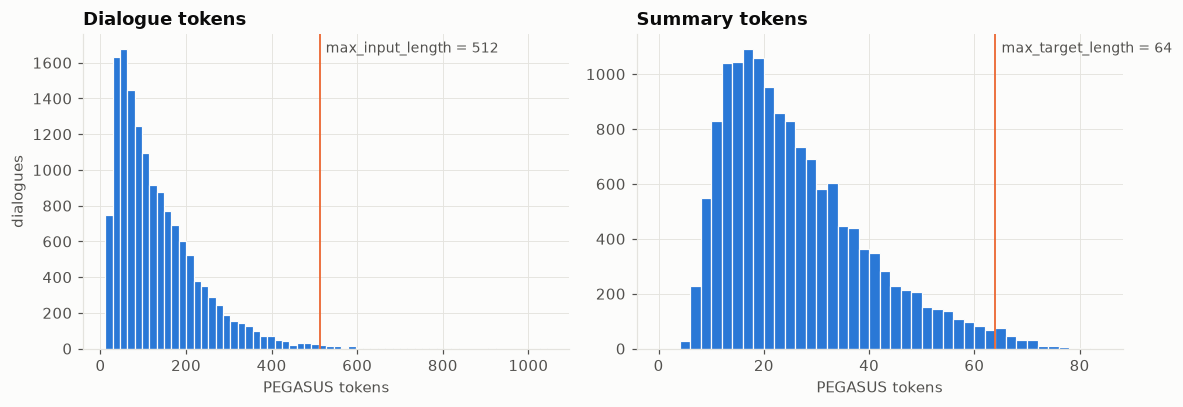

In [11]:
fig, (a1, a2) = plt.subplots(1, 2, figsize=(11, 3.8))
hist(a1, train["dialogue_tokens"], bins=60)
mark(a1, MAX_IN, f"max_input_length = {MAX_IN}", color=ORANGE, ls="-")
a1.set_title("Dialogue tokens"); a1.set_xlabel("PEGASUS tokens"); a1.set_ylabel("dialogues")
hist(a2, train["summary_tokens"], bins=range(0, 86, 2))  # integer-aligned bins avoid aliasing gaps
mark(a2, MAX_OUT, f"max_target_length = {MAX_OUT}", color=ORANGE, ls="-")
a2.set_title("Summary tokens"); a2.set_xlabel("PEGASUS tokens")
savefig(fig, "04_token_lengths")

> **Insight → decision.** Dialogues average about **1.4 tokens per word** (names, slang and emoticons split into
> pieces).
>
> * `max_input_length: 512` keeps **99.3%** of training dialogues whole (95 of 14.6k are truncated). Going to 1024
>   would cost ~4× more attention compute and memory for 0.65% of rows. Not worth it on a 16 GB T4.
> * `max_target_length: 64` covers **98.8%** of summaries; the ~1% that are cut lose only their last few tokens.
> * Generation uses `max_length: 64` to match: the model is never asked for something longer than it was trained on.

## 6. Compression ratio and the length relationship

compression ratio (dialogue words / summary words): median 3.90, mean 4.84, p5 1.56, p95 11.24, max 55.1


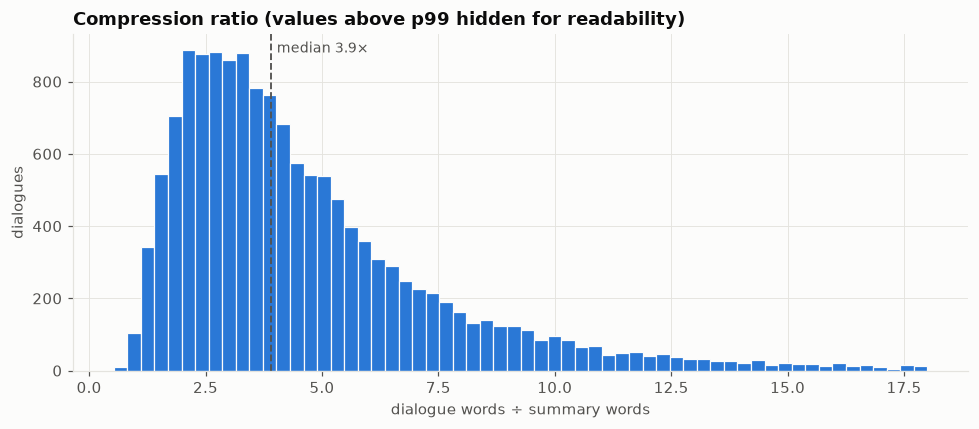

In [12]:
cr = train["compression_ratio"]
print(f"compression ratio (dialogue words / summary words): median {cr.median():.2f}, mean {cr.mean():.2f}, "
      f"p5 {cr.quantile(.05):.2f}, p95 {cr.quantile(.95):.2f}, max {cr.max():.1f}")
fig, ax = plt.subplots()
clip = cr.quantile(.99)
hist(ax, cr[cr <= clip], bins=60)
mark(ax, cr.median(), f"median {cr.median():.1f}×")
ax.set_title("Compression ratio (values above p99 hidden for readability)")
ax.set_xlabel("dialogue words ÷ summary words"); ax.set_ylabel("dialogues")
savefig(fig, "05_compression_ratio")

Pearson r = 0.607   Spearman ρ = 0.659


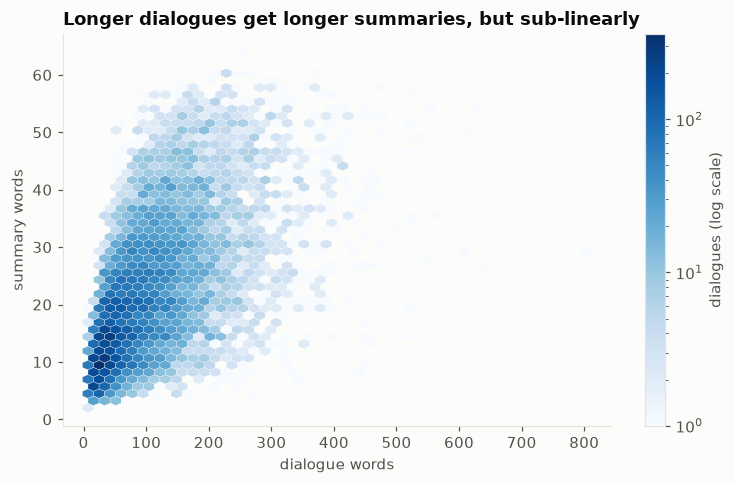

In [13]:
pearson = train.dialogue_words.corr(train.summary_words)
spearman = train.dialogue_words.rank().corr(train.summary_words.rank())
print(f"Pearson r = {pearson:.3f}   Spearman ρ = {spearman:.3f}")

fig, ax = plt.subplots(figsize=(7, 4.5))
hb = ax.hexbin(train.dialogue_words, train.summary_words, gridsize=45, cmap="Blues", mincnt=1, bins="log",
               linewidths=0.2, edgecolors=SURFACE)
fig.colorbar(hb, ax=ax, label="dialogues (log scale)")
ax.set_title("Longer dialogues get longer summaries, but sub-linearly")
ax.set_xlabel("dialogue words"); ax.set_ylabel("summary words"); ax.grid(visible=False)
savefig(fig, "06_length_relationship")

> **Insight.** A typical summary is about **4× shorter** than its dialogue (median ratio 3.9). The ratio varies widely,
> though (p5 ≈ 1.6×, p95 ≈ 11×), so summary length is not a fixed fraction of the input. Length correlates moderately
> (Spearman ρ ≈ 0.66): long chats get somewhat longer summaries, but the curve flattens because the 64-word ceiling
> binds. This motivates two experiments in Phase 4: `length_penalty`, which controls how much beam search favours
> longer outputs, and `min_length`. The same compression ratio is reported by the API for every request.

## 7. Dialogue structure: turns and speakers

            count  mean  std  min  25%   50%   75%   max
turns     14635.0  11.2  6.5  3.0  6.0  10.0  15.0  46.0
speakers  14635.0   2.4  0.8  2.0  2.0   2.0   3.0  14.0


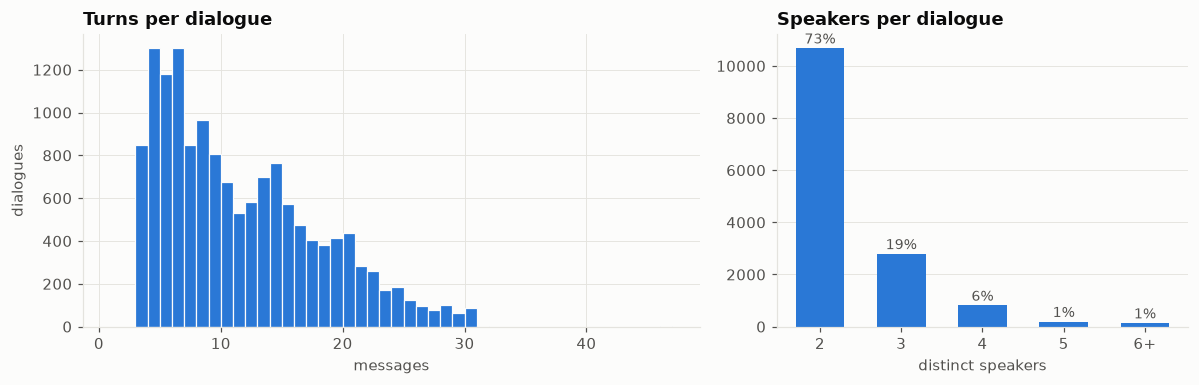

In [14]:
train["turns"] = train["dialogue"].str.count("\n") + 1
train["speakers"] = train["dialogue"].apply(
    lambda d: len({line.split(":", 1)[0].strip() for line in d.split("\n") if ":" in line}))
print(train[["turns", "speakers"]].describe().round(1).T)

fig, (a1, a2) = plt.subplots(1, 2, figsize=(11, 3.6), gridspec_kw={"width_ratios": [3, 2]})
hist(a1, train["turns"], bins=range(1, 48))
a1.set_title("Turns per dialogue"); a1.set_xlabel("messages"); a1.set_ylabel("dialogues")
counts = train["speakers"].clip(upper=6).value_counts().sort_index()
labels = [str(k) if k < 6 else "6+" for k in counts.index]
a2.bar(labels, counts.values, color=BLUE, width=0.6)
for x, v in enumerate(counts.values):
    a2.annotate(f"{v / len(train):.0%}", (x, v), xytext=(0, 3), textcoords="offset points", ha="center",
                color=INK_2, fontsize=9)
a2.set_title("Speakers per dialogue"); a2.set_xlabel("distinct speakers"); a2.grid(axis="x", visible=False)
savefig(fig, "07_turns_speakers")

In [15]:
mentions = np.mean([
    any(name.lower() in s.lower() for name in {l.split(":", 1)[0].strip() for l in d.split("\n") if ":" in l})
    for d, s in zip(train.dialogue, train.summary)])
print(f"summaries that mention at least one speaker by name: {mentions:.1%}")

summaries that mention at least one speaker by name: 97.1%


> **Insight.** About 73% of conversations are between **two people**; group chats (3 to 14 speakers) form a long tail.
> A median dialogue has 10 messages. **97%** of reference summaries name at least one speaker, so the model must learn
> *who did what*. That means speaker names must survive cleaning (no lowercasing, since PEGASUS is cased; no stripping
> of the `Name:` prefixes). Attributing actions to the wrong speaker is the typical error to look for in Phase 4 samples.

## 8. Word frequency and most common words

vocabulary size: dialogues 26,809 words, summaries 16,822 words


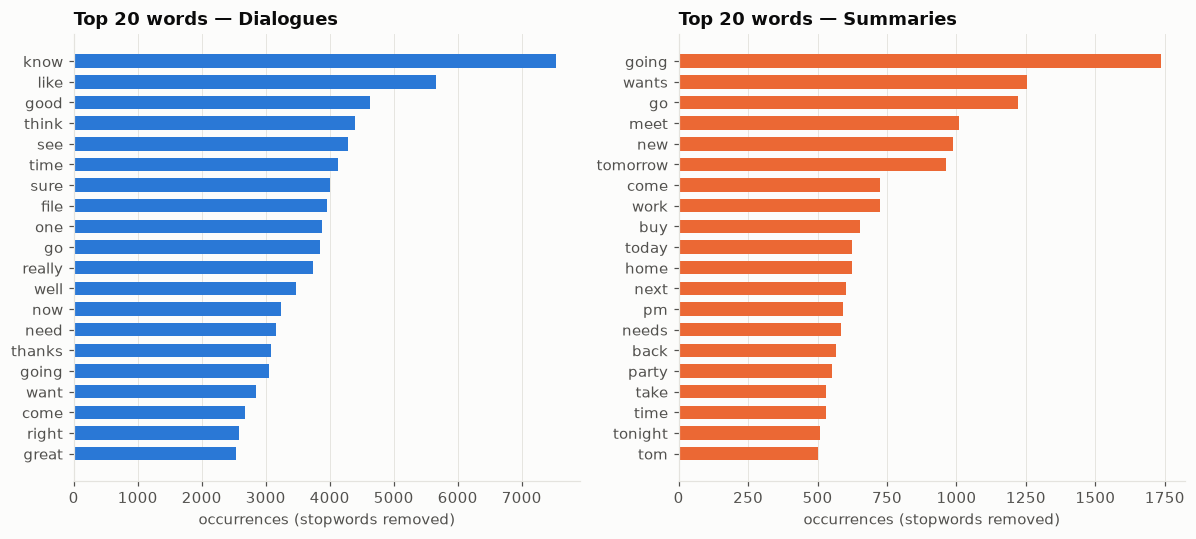

In [16]:
STOPWORDS = set('''a about above after again against all am an and any are aren't as at be because been before
being below between both but by can can't cannot could couldn't did didn't do does doesn't doing don't down during
each few for from further had hadn't has hasn't have haven't having he he'd he'll he's her here here's hers herself
him himself his how how's i i'd i'll i'm i've if in into is isn't it it's its itself let's me more most mustn't my
myself no nor not of off on once only or other ought our ours ourselves out over own same shan't she she'd she'll
she's should shouldn't so some such than that that's the their theirs them themselves then there there's these they
they'd they'll they're they've this those through to too under until up very was wasn't we we'd we'll we're we've
were weren't what what's when when's where where's which while who who's whom why why's with won't would wouldn't
you you'd you'll you're you've your yours yourself yourselves will just ok okay yes yeah oh u im dont get got also
'''.split())

def tokens(text):
    return re.findall(r"[a-z][a-z']+", text.lower())

dialogue_body = train["dialogue"].str.replace(r"(?m)^[^:\n]{1,40}:", " ", regex=True)  # drop "Name:" prefixes
dlg_counts = Counter(t for text in dialogue_body for t in tokens(text) if t not in STOPWORDS)
sum_counts = Counter(t for text in train["summary"] for t in tokens(text) if t not in STOPWORDS)
print(f"vocabulary size: dialogues {len(dlg_counts):,} words, summaries {len(sum_counts):,} words")

fig, (a1, a2) = plt.subplots(1, 2, figsize=(11, 5))
for ax, counter, color, title in [(a1, dlg_counts, BLUE, "Dialogues"), (a2, sum_counts, ORANGE, "Summaries")]:
    words, freq = zip(*counter.most_common(20)[::-1])
    ax.barh(words, freq, color=color, height=0.65)
    ax.set_title(f"Top 20 words — {title}"); ax.set_xlabel("occurrences (stopwords removed)")
    ax.grid(axis="y", visible=False)
savefig(fig, "08_top_words")

In [17]:
media = Counter(tag.lower() for text in train["dialogue"] for tag in re.findall(r"<[^>\s]{1,30}>", text))
emoticon_share = train["dialogue"].str.contains(r"[:;]-?[)(DPp]").mean()
print(f"dialogues containing an emoticon like :) ;-) :D -> {emoticon_share:.0%}")
pd.Series(dict(media.most_common(12)), name="occurrences").to_frame()

dialogues containing an emoticon like :) ;-) :D -> 38%


,occurrences
<file_photo>,1735
<file_gif>,855
<file_other>,803
<file_video>,213
<file_picture>,62
<photo_file>,62
<file_link>,31
<gif>,20
<file_image>,19
<file:photo>,18


> **Insight.** The two vocabularies differ in a telling way. Dialogues are dominated by conversational words
> (*know, like, good, think, see, time*). Summaries are dominated by intentions and plans, written in the third
> person (*going, wants, meet, tomorrow, needs, tonight*). That shift is exactly the abstractive rewrite the model must learn: "I'll come at 5" →
> "Tom will come at 5 pm."
>
> The text is **informal**: about 38% of dialogues contain emoticons, plus slang and typos. Attachments appear as tags
> with about a dozen different spellings (`<file_photo>`, `<file_gif>`, `<photo_file>`, `<file:photo>`, `<gif>` …).
> That is also why *file* ranks among the top dialogue words. These are
> not HTML and must not be deleted, because summaries refer to them ("Anna sends a photo of the cake"). Phase 3
> cleaning will *standardise* the variants instead of stripping them.

## 9. How abstractive are the summaries?

A **novel n-gram** is a sequence of *n* words in the summary that never occurs in its dialogue. Purely extractive
summaries (copying sentences) would have about 0% novel n-grams.

{'1-gram': '34.1%', '2-gram': '78.3%', '3-gram': '90.0%', '4-gram': '95.2%'}


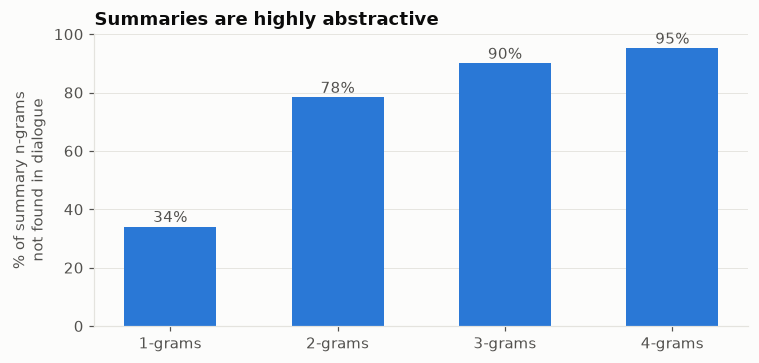

In [18]:
def novel_ngram_rate(dialogue, summary, n):
    d, s = tokens(dialogue), tokens(summary)
    d_grams = set(zip(*[d[i:] for i in range(n)]))
    s_grams = list(zip(*[s[i:] for i in range(n)]))
    return np.mean([g not in d_grams for g in s_grams]) if s_grams else np.nan

novelty = {n: np.nanmean([novel_ngram_rate(d, s, n) for d, s in zip(train.dialogue, train.summary)])
           for n in (1, 2, 3, 4)}
print({f"{n}-gram": f"{v:.1%}" for n, v in novelty.items()})

fig, ax = plt.subplots(figsize=(7, 3.4))
ax.bar([f"{n}-grams" for n in novelty], [v * 100 for v in novelty.values()], color=BLUE, width=0.55)
for x, v in enumerate(novelty.values()):
    ax.annotate(f"{v:.0%}", (x, v * 100), xytext=(0, 3), textcoords="offset points", ha="center", color=INK_2)
ax.set_ylim(0, 100); ax.set_ylabel("% of summary n-grams\nnot found in dialogue")
ax.set_title("Summaries are highly abstractive"); ax.grid(axis="x", visible=False)
savefig(fig, "09_novel_ngrams")

> **Insight.** About a third (34%) of summary *words* and 78% of summary *bigrams* never appear in the dialogue. An
> extractive method (picking the best lines) has a hard ceiling here: it cannot produce "Amanda will bring Jerry
> cookies" from "Amanda: I'll bring you tomorrow :-)". This is the quantitative argument for an **abstractive
> seq2seq model** like PEGASUS. It also explains why ROUGE-2 scores on SAMSum are much lower than ROUGE-1 for every
> model: exact bigram overlap is inherently scarce.

## 10. Outlier analysis

In [19]:
q1, q3 = train["dialogue_words"].quantile([.25, .75])
fence = q3 + 1.5 * (q3 - q1)
outliers = train[train["dialogue_words"] > fence]
print(f"IQR upper fence: {fence:.0f} words -> {len(outliers)} outlier dialogues ({len(outliers)/len(train):.1%}), "
      f"of which {(outliers.dialogue_tokens > MAX_IN).sum()} exceed {MAX_IN} tokens")

cols = ["id", "dialogue_words", "summary_words", "compression_ratio", "summary"]
print("\nHighest compression (very long dialogue, very short summary):")
display(train.nlargest(3, "compression_ratio")[cols])
print("Lowest compression (summary as long as / longer than the dialogue):")
display(train.nsmallest(3, "compression_ratio")[cols])

IQR upper fence: 259 words -> 548 outlier dialogues (3.7%), of which 95 exceed 512 tokens

Highest compression (very long dialogue, very short summary):


,id,dialogue_words,summary_words,compression_ratio,summary
14515,13829489,441,8,55.125000,Julia dreamed about a party at a bar.
1157,13716492,269,5,53.800000,Caroline has a strep throat.
3675,13715942,339,7,48.428571,Danielle and Brooke will pick up Kristen.


Lowest compression (summary as long as / longer than the dialogue):


,id,dialogue_words,summary_words,compression_ratio,summary
9039,13611810,9,17,0.529412,Harry and Patrick are excited about the win. T...
1038,13864828,8,12,0.666667,Natalie and Kyle are waiting for Luke. He'll c...
7708,13716219,10,15,0.666667,Aria sends Eric and Miley a photo of puppies. ...


In [20]:
row = train.nsmallest(1, "compression_ratio").iloc[0]
print(f"DIALOGUE:\n{row.dialogue}\n\nSUMMARY:\n{row.summary}")

DIALOGUE:
Harry: WE WOOOOOOOOOOOOOOOOON!!!
Patrick: YEEEEEEAH!!!!
Harry: Beer?
Patrick: Coming

SUMMARY:
Harry and Patrick are excited about the win. They are going to meet up for a beer.


> **Insight.** About 3.7% of dialogues are statistical outliers by the IQR rule. They are **legitimately long
> conversations**, not errors, so they are kept. Only the few beyond 512 tokens get truncated. The interesting outliers
> are at the *ratio* extremes:
>
> * *Very high compression* (e.g. a 300+ word chat summarised in a few words) means the conversation was chit-chat
>   with one actionable fact.
> * *Ratio < 1* means a terse exchange (emoji, "(y)") that the annotator expanded with context. Those 61 rows are
>   flagged as warnings in the validation report rather than dropped: they are rare, human-written, and teach the model
>   to unpack shorthand.
>
> Neither group justifies removal. Dropping hard examples would make test scores look better while making the model
> worse on real inputs.

## 11. Key takeaways → decisions

| Finding | Decision (where) |
|---|---|
| 93 train rows duplicate validation/test dialogues | Remove from train: `remove_cross_split_leakage: true` (validation) |
| Junk summaries ("test", "yyy") | `min_summary_words: 2` (validation) |
| Repeated dialogues have *different* summaries | Keep: multiple references, only exact pairs dropped |
| 99.3% of dialogues ≤ 512 tokens | `max_input_length: 512` (preprocessing) |
| 98.8% of summaries ≤ 64 tokens | `max_target_length: 64`, generation `max_length: 64` |
| Summaries ~4× shorter, highly variable | Tune `length_penalty` / `min_length` in Phase 4; report compression ratio in the API |
| 97% of summaries name speakers; PEGASUS is cased | No lowercasing; keep `Name:` prefixes |
| ~12 spellings of attachment tags; not HTML | Standardise tags in Phase 3 cleaning instead of stripping them |
| 34% novel words, 78% novel bigrams | Abstractive model required; expect ROUGE-2 ≪ ROUGE-1 |
| Splits have matching distributions | Keep the official split; test scores are representative |